In [1]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="gpt-oss:120b-cloud")
print('Model is ready to use!')

Model is ready to use!


In [2]:
# STEP-1: Define the state
from typing import TypedDict

class NumState(TypedDict):
    num: int
    odd: bool

print('Graph state is ready .. ')

Graph state is ready .. 


In [3]:
# STEP-2: Define the nodes

def check_num(state: NumState) -> dict:
    """Just check the number"""
    print(f'The number is: {state["num"]}')
    return { "num": state["num"] }

def even_num(state: NumState) -> dict:
    """Just say I'm even"""
    print(f'Oh! I am even one...')
    return { "num": state["num"], "odd": False }

def odd_num(state: NumState) -> dict:
    """Just say I'm odd"""
    print(f'Oh! I am odd one...')
    return { "num": state["num"], "odd": True }

def route_conditional_check(state: NumState) -> str:
     """Just checkign if num is odd or even"""
     num_val = state["num"]
     if num_val % 2 == 0:
         return "even"
     else:
         return "odd"

print('Graph Nodes are ready')

Graph Nodes are ready


Graph is ready...


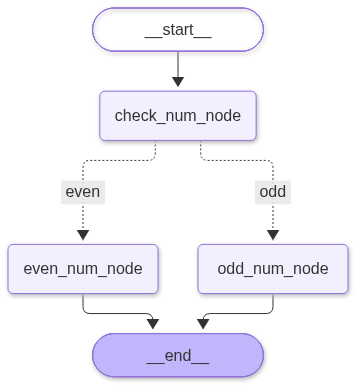

In [4]:
# STEP-3: Add edges and build the graph
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode

graph_builder = StateGraph(NumState)

# Node registration
graph_builder.add_node("check_num_node", check_num)
graph_builder.add_node("even_num_node", even_num)
graph_builder.add_node("odd_num_node", odd_num)

# Add edges
graph_builder.add_edge(START, "check_num_node")
graph_builder.add_conditional_edges(
    "check_num_node",
    route_conditional_check,
    {
        "even": "even_num_node",
        "odd": "odd_num_node"
    }
)
graph_builder.add_edge("even_num_node", END)
graph_builder.add_edge("odd_num_node", END)
# graph_builder.add_edge("check_num_node", END)

graph = graph_builder.compile()
print('Graph is ready...')
graph

In [5]:
response = graph.invoke({
    "num": 21
})
response

The number is: 21
Oh! I am odd one...


{'num': 21, 'odd': True}

In [6]:
response = graph.invoke({
    "num": 24
})
response

The number is: 24
Oh! I am even one...


{'num': 24, 'odd': False}